
# Climate Physical Risk — Company-level Exploration and Regulatory Compliance

This notebook:
- Authenticates with the **Riskthinking.AI VELO Python SDK**
- Pulls **assets**, **climate scores**, and **impact (hazard) scores**
- Parses `index_risks` into tidy form
- Computes **materiality** (policy-based), **top hazards company-wide**, and **hazards affecting material assets**
- Saves tables, figures, and maps for regulatory evidence


# 1. Setup, Data Import and Preprocessing

In [ ]:
# Install dependencies (run this once if needed)
%pip install velo-sdk matplotlib polars python-dotenv pyarrow contextily geopandas seaborn plotly --quiet

# Note: After installing new packages, you may need to restart the kernel before running the rest of the notebook.

In [7]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Environment & Imports
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Install/import dependencies and configure plotting.
# Inputs  : None
# Outputs : Imported modules; Matplotlib configured.

from __future__ import annotations

import os
from dataclasses import dataclass
from typing import Optional, Dict, Any, List, Iterable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

import ast
import re

from dotenv import load_dotenv
from velo_sdk.api import APIClient

# Matplotlib defaults
%config InlineBackend.figure_format = 'svg'
plt.rcParams.update({"figure.autolayout": True, "axes.grid": True})



## Parameters

- Specify Company name, horizons, pathways, and metrics to analyze.
- Materiality policy defaults: VaR95 > 50% at 2050 under any selected pathway.
- Ensure OUTPUT_DIR is defined. Defaults to "outputs" directory in current directory.


In [ ]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Parameters
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Define company, scenario, explicit metric headers, user selection, and outputs.
# Inputs  : User-edited constants.
# Outputs : Global params/constants for the run.

""" 
Specify the following parameters for importing climate risk data:

HORIZONS: 2025 to 2100 in steps of 5. See Data Coverage section of documentation for full list of values.
Multiple horizons may be selected in a list format, for example, [2025, 2040, 2050]. 
However, this notebook is designed to analyze a single horizon

PATHWAYS: String specifying the scenario pathway. See Data Coverage section of documentation for full list 
of string values.

METRICS: String specifying aggregated asset-level metric to import. See Data Coverage section of documentation 
for full list of string values. Multiple metrics may be selected in a list format containing a single 
comma-separated string, for example, ["dcr_score,expected_impact"]. Leave blank in the function call to import 
all available metrics.
"""

# Company & scope
COMPANY_NAME: str = "Pfizer"    # fuzzy match OK, but exact match ensures best results
PATHWAYS: list[str] = ["<2 degrees", ">4 degrees"]
HORIZONS: list[int] = [2025, 2035, 2050]

# Explicit metric headers present in climate_df
ALL_METRICS: list[str] = [
    "dcr_score",
    "expected_impact",
    "cvar_99",
    "cvar_95",
    "cvar_50",
    "var_99",
    "var_95",
    "var_50",
]

# Default selected metrics (user can edit)
METRICS: list[str] = ["expected_impact", "cvar_95", "var_95"]
assert all(m in ALL_METRICS for m in METRICS), "Invalid metric(s) selected"

# Materiality policy (no dependence on 'is_significant')
MATERIALITY_HORIZON: int = 2050
MATERIALITY_THRESHOLD_VAR95: float = 0.50
MATERIALITY_PATHWAYS: list[str] = PATHWAYS[:]

# Output dir
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)



## Authentication

Reads `RISKTHINKING_API_KEY` from environment (supports `.env`). 
Ensure .env file in home directory contains RISKTHINKING_API_KEY.
Initializes SDK client.


In [9]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Authentication & Client
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Initialize VELO SDK client.
# Inputs  : Environment variable RISKTHINKING_API_KEY.
# Outputs : `client` ready for API calls.


load_dotenv()  # reads RISKTHINKING_API_KEY if present
client = APIClient()  # or APIClient(api_key="...")
print("Client ready.")


Client ready.



## Helpers

Utilities to convert SDK iterators, load assets/climate/impact, parse `index_risks`,
and map index names to standardized hazards. The client's **Python SDK** is used throughout.


In [10]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Helpers (SDK Iterators, Parsing, Metrics)
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Provide SDK utilities and parsers used throughout the analysis.
# Inputs  : SDK responses; raw `index_risks` strings.
# Outputs : Helper functions for loading and parsing.


@dataclass(frozen=True)
class ScenarioRequest:
    """Container for a scenario slice.

    Parameters
    ----------
    pathway : str
        Scenario pathway identifier (e.g., "ssp126").
    horizon : int
        Year horizon (e.g., 2035, 2050).
    """
    pathway: str
    horizon: int

def iter_to_records(iterator: Iterable) -> List[Dict[str, Any]]:
    """Materialize a VELO SDK iterator into a list of dictionaries."""
    records: List[Dict[str, Any]] = []
    for item in iterator:
        if hasattr(item, "model_dump"):     # pydantic v2
            records.append(item.model_dump())
        elif hasattr(item, "dict"):         # pydantic v1
            records.append(item.dict())
        elif isinstance(item, dict):
            records.append(item)
        else:
            try:
                records.append(vars(item))
            except Exception:
                records.append({"value": item})
    return records

def first_company_id(client: APIClient, name: str) -> str:
    """Resolve a fuzzy company name to a company ID."""
    matches = client.companies.search_companies(name=name, limit=1)
    if not matches:
        raise ValueError(f"No company found for name={name!r}")
    return matches[0].id

def load_assets(client: APIClient, company_id: str) -> pd.DataFrame:
    """Retrieve and standardize asset-level data for a company."""
    it = client.companies.list_company_assets(company_id=company_id)
    df = pd.DataFrame(iter_to_records(it))
    # Ensure core fields exist
    for c in ["id","name","latitude","longitude","country","state","city","address","asset_type","asset_value"]:
        if c not in df.columns:
            df[c] = np.nan if c in {"latitude","longitude","asset_value"} else None
    # NOTE: We do NOT filter or require 'is_significant'
    return df

def load_climate_scores(client: APIClient, company_id: str, req: ScenarioRequest, metrics: list[str] | None = None) -> pd.DataFrame:
    """Query climate impact scores for all assets under a specified scenario.

    Parameters
    ----------
    client : APIClient
        Authenticated VELO API client instance.
    company_id : str
        Target company ID.
    req : ScenarioRequest
        Scenario pathway and horizon selection.
    metrics : list[str] | None
        Optional column subset to keep.

    Returns
    -------
    pd.DataFrame
        Asset-level climate scores with `pathway` and `horizon` columns.
    """
    it = client.companies.list_company_asset_climate_scores(
        company_id=company_id, pathway=req.pathway, horizon=req.horizon, page_size=1000
    )
    df = pd.DataFrame(iter_to_records(it))
    df["pathway"] = str(req.pathway).lower()
    df["horizon"] = req.horizon
    if metrics:
        base = {"asset_id","pathway","horizon","country","state","city","address","asset_type"}
        keep = list(base.intersection(df.columns)) + [c for c in metrics if c in df.columns]
        if keep:
            df = df[keep]
    return df

def load_impact_scores(client: APIClient, company_id: str, req: ScenarioRequest) -> pd.DataFrame:
    """Query physical hazard impact scores for all assets under a specified scenario.

    Returns a DataFrame with raw `index_risks` that contains index-level contributions/attributions.
    """
    it = client.companies.list_company_asset_impact_scores(
        company_id=company_id, pathway=req.pathway, horizon=req.horizon, page_size=1000
    )
    df = pd.DataFrame(iter_to_records(it))
    df["pathway"] = str(req.pathway).lower()
    df["horizon"] = req.horizon
    return df

def parse_index_risks_cell(txt: str) -> List[Dict[str, Any]]:
    """Parse a raw `index_risks` cell (string) into a list of dicts."""
    blocks = re.findall(r"\{[^{}]*\}", str(txt), flags=re.DOTALL)
    items: List[Dict[str, Any]] = []
    for b in blocks:
        try:
            items.append(ast.literal_eval(b))
        except Exception:
            b2 = b.replace("\n"," ").replace("\r"," ")
            try:
                items.append(ast.literal_eval(b2))
            except Exception:
                pass
    return items

def map_index_to_hazard(name: str) -> str:
    """Map a raw index name to a standardized hazard label."""
    s = str(name).lower()
    if "cyclone" in s: return "Cyclone"
    if "rx1day" in s or "precip" in s: return "Extreme Precipitation"
    if "hot_day" in s or "hot_days" in s or "heat" in s: return "Extreme Heat"
    if "frost" in s or "cold" in s: return "Extreme Cold"
    if "wind_max_daily_max" in s or "wind" in s: return "Extreme Wind"
    if "cflood" in s: return "Coastal Flood"
    if "rflood" in s: return "Riverine Flood"
    if "sea_level" in s: return "Sea Level Rise"
    if "dlyfrzthw" in s: return "Freeze Thaw Cycle"
    if "wildfire" in s or "fwi" in s: return "Wildfire"
    return "UNKNOWN"



## Pull data

- Resolve company ID
- Pull assets
- Pull climate & impact scores for each (pathway × horizon)


In [11]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Load Company & Pull Assets/Climate/Impact
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Fetch assets and scores across selected scenarios.
# Inputs  : COMPANY_NAME, PATHWAYS, HORIZONS, METRICS.
# Outputs : `assets_df`, `climate_df`, `impact_df` + CSV snapshots.


company_id = first_company_id(client, COMPANY_NAME)
print("Company ID:", company_id)

assets_df = load_assets(client, company_id)
print("Assets:", assets_df.shape)

climate_frames: List[pd.DataFrame] = []
impact_frames: List[pd.DataFrame] = []
for p in PATHWAYS:
    for h in HORIZONS:
        req = ScenarioRequest(p, h)
        climate_frames.append(load_climate_scores(client, company_id, req, metrics=METRICS))
        impact_frames.append(load_impact_scores(client, company_id, req))

climate_df = pd.concat(climate_frames, ignore_index=True)
impact_df  = pd.concat(impact_frames, ignore_index=True)

climate_df.to_csv(f"{OUTPUT_DIR}/climate_scores_raw.csv", index=False)
impact_df.to_csv(f"{OUTPUT_DIR}/impact_scores_raw.csv", index=False)
assets_df.to_csv(f"{OUTPUT_DIR}/assets_raw.csv", index=False)

print("Climate:", climate_df.shape, "Impact:", impact_df.shape)
climate_df.head()


Company ID: d746c477-dd18-48da-bcd1-b9db3af869d9
Assets: (124, 16)
Climate: (744, 11) Impact: (744, 4)


,city,asset_id,pathway,country,asset_type,state,horizon,address,expected_impact,cvar_95,var_95
0,Dubai,006266fb-c9ac-425f-ab82-f4c66fac5dba,<2 degrees,ARE,Pharmaceutical and Medicine Manufacturing,Dubai,2025,"Office 401, Building 5WA, Dubai Airport Free Z...",0.033460,0.050502,0.050502
1,Tullamore,038a5d3c-0fbe-4748-b605-fb2ef1638f3d,<2 degrees,IRL,Pharmaceutical and Medicine Manufacturing,Co. Offaly,2025,"5, Sragh Business & Technology Park, Rahan Rd,...",0.027095,0.128459,0.127410
2,Tampa,04fb0881-8e4e-46fb-b2e6-fef4d4c3e286,<2 degrees,USA,Pharmaceutical and Medicine Manufacturing,Florida,2025,"2002 N Tampa St, Tampa, FL 33602, United States",0.174807,0.393147,0.391460
3,Memphis,0713530c-9377-4d16-81ec-2746bbe7aaac,<2 degrees,USA,Pharmaceutical and Medicine Manufacturing,Tennessee,2025,"949 S Shady Grove Rd, Memphis, Tennessee, 3812...",0.011227,0.042991,0.019417
4,Secaucus,0c064533-8506-4074-a06d-87d25cad7cbb,<2 degrees,USA,Pharmaceutical and Medicine Manufacturing,New Jersey,2025,"15 Enterprise Ave N, Secaucus, New Jersey, 070...",0.112276,0.278864,0.275022



## Standardize climate

- Ensure `asset_id`
- Normalize types
- **Assign explicit metric columns** (no auto-detection)
- Keep tidy subset including selected `METRICS`


In [12]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Standardize Climate (Explicit Metrics)
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Produce a tidy climate_df with explicit metric columns.
# Inputs  : `climate_df`, METRICS.
# Outputs : Cleaned `climate_df`.


# Ensure asset_id exists
if "asset_id" not in climate_df.columns and "id" in climate_df.columns:
    climate_df = climate_df.rename(columns={"id": "asset_id"})
if "asset_id" not in climate_df.columns:
    raise KeyError("Climate scores are missing 'asset_id'.")

# Normalize dtypes
climate_df["pathway"] = climate_df["pathway"].astype(str).str.lower()
climate_df["horizon"] = pd.to_numeric(climate_df["horizon"], errors="coerce")

# Explicit assignment for key metrics (still allow user-selected METRICS elsewhere)
expected_col = "expected_impact"
var95_col    = "var_95"
cvar95_col   = "cvar_95"
print("Using explicit metrics:", {"expected": expected_col, "var95": var95_col, "cvar95": cvar95_col})

keep = ["asset_id","pathway","horizon","country","state","city","address","asset_type"]
# ensure we also keep user-selected METRICS if present
for c in set([expected_col, var95_col, cvar95_col] + METRICS):
    if c in climate_df.columns:
        keep.append(c)
climate_df = climate_df[[c for c in keep if c in climate_df.columns]].copy()

climate_df.head()


Using explicit metrics: {'expected': 'expected_impact', 'var95': 'var_95', 'cvar95': 'cvar_95'}


,asset_id,pathway,horizon,country,state,city,address,asset_type,var_95,cvar_95,expected_impact
0,006266fb-c9ac-425f-ab82-f4c66fac5dba,<2 degrees,2025,ARE,Dubai,Dubai,"Office 401, Building 5WA, Dubai Airport Free Z...",Pharmaceutical and Medicine Manufacturing,0.050502,0.050502,0.033460
1,038a5d3c-0fbe-4748-b605-fb2ef1638f3d,<2 degrees,2025,IRL,Co. Offaly,Tullamore,"5, Sragh Business & Technology Park, Rahan Rd,...",Pharmaceutical and Medicine Manufacturing,0.127410,0.128459,0.027095
2,04fb0881-8e4e-46fb-b2e6-fef4d4c3e286,<2 degrees,2025,USA,Florida,Tampa,"2002 N Tampa St, Tampa, FL 33602, United States",Pharmaceutical and Medicine Manufacturing,0.391460,0.393147,0.174807
3,0713530c-9377-4d16-81ec-2746bbe7aaac,<2 degrees,2025,USA,Tennessee,Memphis,"949 S Shady Grove Rd, Memphis, Tennessee, 3812...",Pharmaceutical and Medicine Manufacturing,0.019417,0.042991,0.011227
4,0c064533-8506-4074-a06d-87d25cad7cbb,<2 degrees,2025,USA,New Jersey,Secaucus,"15 Enterprise Ave N, Secaucus, New Jersey, 070...",Pharmaceutical and Medicine Manufacturing,0.275022,0.278864,0.112276


# 2. Analysis and Outputs


## Parse `index_risks` & compute leading hazard

- Explode `index_risks`
- Map `index_name` → standardized hazard
- Use contributions to determine leading hazards per (asset, pathway, horizon)


In [13]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Parse index_risks & Leading Hazard
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Create a tidy index-level table and the per-asset leading hazard.
# Inputs  : `impact_df` (raw `index_risks`).
# Outputs : `hazard_long`, `leading_hazard_df`.


impact_df["pathway"] = impact_df["pathway"].astype(str).str.lower()
impact_df["horizon"] = pd.to_numeric(impact_df["horizon"], errors="coerce")

rows: List[Dict[str, Any]] = []
for _, r in impact_df.iterrows():
    val = r.get("index_risks", None)
    if val is None or (isinstance(val, float) and pd.isna(val)):
        continue
    for d in parse_index_risks_cell(str(val)):
        rows.append({
            "asset_id": r.get("asset_id"),
            "pathway":  r.get("pathway"),
            "horizon":  r.get("horizon"),
            "index_name": d.get("index_name"),
            # contributions (impact on multifactor metric)
            "index_impact_expected": d.get("index_impact_expected"),
            "index_impact_cvar_95": d.get("index_impact_cvar_95"),
            "index_impact_var_95": d.get("index_impact_var_95"),
            # attributions (% share of multifactor metric)
            "index_attribution_expected": d.get("index_attribution_expected"),
            "index_attribution_cvar_95": d.get("index_attribution_cvar_95"),
            "index_attribution_var_95": d.get("index_attribution_var_95"),
        })
hazard_long = pd.DataFrame(rows)

hazard_long["hazard"] = hazard_long["index_name"].map(map_index_to_hazard)

# A generic "hazard_score" for ranking leading hazards (prefer contributions; fallback to attributions)
hazard_long["hazard_score"] = (
    pd.to_numeric(hazard_long["index_impact_var_95"], errors="coerce")
      .fillna(pd.to_numeric(hazard_long["index_impact_cvar_95"], errors="coerce"))
      .fillna(pd.to_numeric(hazard_long["index_impact_expected"], errors="coerce"))
      .fillna(pd.to_numeric(hazard_long["index_attribution_var_95"], errors="coerce"))
      .fillna(pd.to_numeric(hazard_long["index_attribution_cvar_95"], errors="coerce"))
      .fillna(pd.to_numeric(hazard_long["index_attribution_expected"], errors="coerce"))
)
hazard_long = hazard_long.dropna(subset=["hazard_score"])

grp = ["asset_id","pathway","horizon"]
idx = hazard_long.groupby(grp)["hazard_score"].idxmax()
leading_hazard_df = hazard_long.loc[idx, ["asset_id","pathway","horizon","hazard","hazard_score"]].reset_index(drop=True)

leading_hazard_df.head()


,asset_id,pathway,horizon,hazard,hazard_score
0,006266fb-c9ac-425f-ab82-f4c66fac5dba,<2 degrees,2025,Extreme Heat,0.034135
1,006266fb-c9ac-425f-ab82-f4c66fac5dba,<2 degrees,2035,Extreme Heat,0.045662
2,006266fb-c9ac-425f-ab82-f4c66fac5dba,<2 degrees,2050,Extreme Heat,0.049727
3,006266fb-c9ac-425f-ab82-f4c66fac5dba,>4 degrees,2025,Riverine Flood,0.117941
4,006266fb-c9ac-425f-ab82-f4c66fac5dba,>4 degrees,2035,Riverine Flood,0.069631



## Merge

Join assets, climate scores, and leading hazards into a single frame.


In [14]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Merge Assets + Climate + Hazards
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Consolidate for downstream analysis.
# Inputs  : `assets_df`, `climate_df`, `leading_hazard_df`.
# Outputs : `merged` + CSV.


merged = climate_df.merge(assets_df, left_on="asset_id", right_on="id", how="left", suffixes=("","_asset"))

# ensure single hazard columns on merge
needed = ["asset_id","pathway","horizon","hazard","hazard_score"]
present = [c for c in needed if c in leading_hazard_df.columns]
merged = merged.drop(columns=[c for c in ["hazard","hazard_score"] if c in merged.columns])
merged = merged.merge(leading_hazard_df[present], on=["asset_id","pathway","horizon"], how="left", copy=False)

merged.to_csv(f"{OUTPUT_DIR}/consolidated_scores.csv", index=False)
merged.head()


,asset_id,pathway,horizon,country,state,city,address,asset_type,var_95,cvar_95,...,asset_value,address_asset,hex_id,country_asset,ipcc_region,materiality_score,created_at,updated_at,hazard,hazard_score
0,006266fb-c9ac-425f-ab82-f4c66fac5dba,<2 degrees,2025,ARE,Dubai,Dubai,"Office 401, Building 5WA, Dubai Airport Free Z...",Pharmaceutical and Medicine Manufacturing,0.050502,0.050502,...,0,"Office 401, Building 5WA, Dubai Airport Free Z...",609176500201062399,ARE,Arabian-Peninsula,100.0,2025-02-14T00:32:10.563482,2025-08-21T23:40:57.233474,Extreme Heat,0.034135
1,038a5d3c-0fbe-4748-b605-fb2ef1638f3d,<2 degrees,2025,IRL,Co. Offaly,Tullamore,"5, Sragh Business & Technology Park, Rahan Rd,...",Pharmaceutical and Medicine Manufacturing,0.127410,0.128459,...,0,"5, Sragh Business & Technology Park, Rahan Rd,...",608411359444467711,IRL,N.Europe,100.0,2025-02-14T00:31:50.026078,2025-08-21T23:40:45.102738,Cyclone,0.127410
2,04fb0881-8e4e-46fb-b2e6-fef4d4c3e286,<2 degrees,2025,USA,Florida,Tampa,"2002 N Tampa St, Tampa, FL 33602, United States",Pharmaceutical and Medicine Manufacturing,0.391460,0.393147,...,0,"2002 N Tampa St, Tampa, FL 33602, United States",609184042029416447,USA,E.North-America,100.0,2025-02-14T00:33:04.669772,2025-08-21T23:44:39.197199,Cyclone,0.372008
3,0713530c-9377-4d16-81ec-2746bbe7aaac,<2 degrees,2025,USA,Tennessee,Memphis,"949 S Shady Grove Rd, Memphis, Tennessee, 3812...",Pharmaceutical and Medicine Manufacturing,0.019417,0.042991,...,0,"949 S Shady Grove Rd, Memphis, Tennessee, 3812...",608660617535946751,USA,C.North-America,100.0,2025-02-14T00:33:39.850680,2025-08-21T23:43:00.356428,Extreme Heat,0.018320
4,0c064533-8506-4074-a06d-87d25cad7cbb,<2 degrees,2025,USA,New Jersey,Secaucus,"15 Enterprise Ave N, Secaucus, New Jersey, 070...",Pharmaceutical and Medicine Manufacturing,0.275022,0.278864,...,0,"15 Enterprise Ave N, Secaucus, New Jersey, 070...",608725923637755903,USA,E.North-America,100.0,2025-02-14T00:34:45.784084,2025-08-21T23:44:17.862424,Cyclone,0.265890



## Company-level metrics

Value-weighted (if `asset_value` exists) averages of user-selected metrics by pathway × horizon.


In [15]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Company-level Metrics
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Compute summary by scenario-horizon for selected metrics.
# Inputs  : `merged`, METRICS.
# Outputs : `company_summary_metrics.csv`.


def weighted_mean(values: pd.Series, weights: Optional[pd.Series]) -> float:
    """Compute a weighted mean with sensible fallback."""
    if weights is None or not pd.api.types.is_numeric_dtype(weights):
        return float(values.mean()) if len(values) else np.nan
    w = weights.fillna(0.0).to_numpy()
    x = values.to_numpy()
    denom = w.sum()
    return float((x * w).sum() / denom) if denom > 0 else float(values.mean())

asset_value_col = "asset_value" if "asset_value" in merged.columns and pd.api.types.is_numeric_dtype(merged["asset_value"]) else None

company_summary_rows: List[Dict[str, Any]] = []
for p in PATHWAYS:
    for h in HORIZONS:
        sub = merged[(merged["pathway"] == p) & (merged["horizon"] == h)]
        row: Dict[str, Any] = {"pathway": p, "horizon": h}
        for m in METRICS:
            if m in sub.columns and pd.api.types.is_numeric_dtype(sub[m]):
                row[m] = weighted_mean(sub[m], merged[asset_value_col] if asset_value_col else None)
        company_summary_rows.append(row)

company_summary = pd.DataFrame(company_summary_rows).sort_values(["pathway","horizon"])
company_summary.to_csv(f"{OUTPUT_DIR}/company_summary_metrics.csv", index=False)
company_summary


,pathway,horizon,expected_impact,cvar_95,var_95
0,<2 degrees,2025,0.090381,0.193180,0.189306
1,<2 degrees,2035,0.093892,0.194692,0.191356
2,<2 degrees,2050,0.098914,0.197455,0.195191
3,>4 degrees,2025,0.163876,0.274206,0.267161
4,>4 degrees,2035,0.165408,0.273534,0.267772
5,>4 degrees,2050,0.174197,0.276998,0.274313



## Materiality (policy)

Define **material assets** as those with `var_95 >= MATERIALITY_THRESHOLD_VAR95` at
`MATERIALITY_HORIZON` under any selected pathway.


In [16]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Materiality (Policy)
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Flag material assets at policy horizon using explicit var_95.
# Inputs  : `merged`
# Outputs : `vuln_ids`, materiality table CSV.


if "var_95" not in merged.columns:
    raise KeyError("Missing 'var_95' in climate scores; cannot compute materiality.")

scope = merged[
    (merged["horizon"] == MATERIALITY_HORIZON)
    & (merged["pathway"].isin([p.lower() for p in MATERIALITY_PATHWAYS]))
].copy()

asset_flags = (
    scope.groupby("asset_id").agg(
        is_material=("var_95", lambda s: int((pd.to_numeric(s, errors="coerce") >= MATERIALITY_THRESHOLD_VAR95).any())),
        asset_type=("asset_type", "first"),
        country=("country", "first"),
        name=("name", "first"),
        latitude=("latitude","first"),
        longitude=("longitude","first"),
    ).reset_index()
)

total_assets = int(asset_flags["asset_id"].nunique())
mat_assets   = int(asset_flags.loc[asset_flags["is_material"] == 1, "asset_id"].nunique())

materiality_table = pd.DataFrame({
    "Category": [
        "Total Physical Assets",
        "… of which materially vulnerable to physical risk",
    ],
    "Count": [total_assets, mat_assets],
    "Percentage": [
        100.0,
        (100.0 * mat_assets / total_assets) if total_assets else 0.0,
    ],
})
materiality_table.to_csv(f"{OUTPUT_DIR}/materiality_table.csv", index=False)

vuln_ids = set(asset_flags.loc[asset_flags["is_material"] == 1, "asset_id"])
len(vuln_ids), materiality_table


(19,
                                             Category  Count  Percentage
 0                              Total Physical Assets    124  100.000000
 1  … of which materially vulnerable to physical risk     19   15.322581)


## Locations & hazards

- Country counts (+ top asset types) for **material assets**
- Hazard table (min/avg/max of VaR95) at the materiality horizon


In [17]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Locations & Hazard Tables
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Summarize locations and hazard drivers among material assets.
# Inputs  : `merged`, `leading_hazard_df`, `vuln_ids`.
# Outputs : `country_table`, `hazard_table` CSVs.


# Countries table
if not vuln_ids:
    country_table = pd.DataFrame(columns=["country", "count", "asset_types"])
else:
    vuln_rows = merged[merged["asset_id"].isin(vuln_ids)].copy()
    country_table = (
        vuln_rows.groupby(["country"])["asset_id"].nunique().reset_index(name="count")
        .sort_values("count", ascending=False)
    )
    types = (
        vuln_rows.groupby(["country","asset_type"])["asset_id"]
                 .nunique().reset_index(name="count")
    )
    labels = (
        types.sort_values(["country","count"], ascending=[True, False])
             .assign(label=lambda d: d["asset_type"].astype(str) + " (" + d["count"].astype(str) + ")")
    )
    top_types = (
        labels.groupby("country").head(3)
              .groupby("country")["label"].agg("; ".join)
              .reset_index().rename(columns={"label": "asset_types"})
    )
    country_table = country_table.merge(top_types, on="country", how="left")
country_table.to_csv(f"{OUTPUT_DIR}/locations_vulnerable_assets_by_country.csv", index=False)

# Hazard table at the materiality horizon
if not vuln_ids:
    hazard_table = pd.DataFrame(columns=["hazard", "Count of Assets at Risk", "Min. VaR", "Avg. VaR", "Max. VaR"])
else:
    hazards_at_horizon = leading_hazard_df[
        (leading_hazard_df["horizon"] == MATERIALITY_HORIZON)
        & (leading_hazard_df["pathway"].isin([p.lower() for p in MATERIALITY_PATHWAYS]))
    ].copy()
    hazards_at_horizon = hazards_at_horizon[hazards_at_horizon["asset_id"].isin(vuln_ids)].copy()

    if "hazard" not in hazards_at_horizon.columns:
        hazards_at_horizon["hazard"] = "UNKNOWN"

    scope_subset = scope[["asset_id","pathway","horizon","var_95"]].copy()
    hz = hazards_at_horizon.merge(scope_subset, on=["asset_id","pathway","horizon"], how="left")
    if "var_95" not in hz.columns:
        hz["var_95"] = np.nan

    hazard_table = (
        hz.groupby("hazard")["var_95"]
          .agg(["count","min","mean","max"])
          .reset_index()
          .rename(columns={"count":"Count of Assets at Risk","min":"Min. VaR","mean":"Avg. VaR","max":"Max. VaR"})
          .sort_values("Avg. VaR", ascending=False)
    )
hazard_table.to_csv(f"{OUTPUT_DIR}/hazards_min_avg_max_var.csv", index=False)

country_table.head(10), hazard_table.head(10)


(  country  count                                        asset_types
 0     PAK      6  Pharmaceutical and Medicine Manufacturing (5);...
 1     IND      5  Management of Companies and Enterprises (2); P...
 2     USA      3  Pharmaceutical and Medicine Manufacturing (2);...
 3     BGD      1      Pharmaceutical and Medicine Manufacturing (1)
 4     COL      1                          Professional Services (1)
 5     GTM      1        Management of Companies and Enterprises (1)
 6     JPN      1      Pharmaceutical and Medicine Manufacturing (1)
 7     PHL      1        Management of Companies and Enterprises (1),
                   hazard  Count of Assets at Risk  Min. VaR  Avg. VaR  \
 0          Coastal Flood                        1  1.134911  1.134911   
 1                Cyclone                       34  0.149419  0.740279   
 3         Riverine Flood                        2  0.529130  0.574836   
 2  Extreme Precipitation                        1  0.068826  0.068826   
 
    Ma

In [19]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Regional Focus — Top IPCC Regions (Vulnerable Assets)   ║
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Identify top IPCC regions by vulnerable assets and drill down.
# Inputs  : merged, leading_hazard_df, vuln_ids, MATERIALITY_HORIZON, MATERIALITY_PATHWAYS
# Outputs : Per-region tables:
#           (1) Sub-Regions ranked by Count + VaR stats
#           (2) Top 3 Hazards ranked by Avg VaR
# Notes   : Writes CSVs to OUTPUT_DIR.


def _coalesce_hazard_cols(df: pd.DataFrame) -> pd.DataFrame:
    """Ensure single 'hazard' and 'hazard_score' columns exist."""
    if "hazard" not in df.columns:
        if "hazard_x" in df.columns:
            df["hazard"] = df["hazard_x"]
        elif "hazard_y" in df.columns:
            df["hazard"] = df["hazard_y"]
        else:
            df["hazard"] = np.nan
    if "hazard_score" not in df.columns:
        if "hazard_score_x" in df.columns:
            df["hazard_score"] = df["hazard_score_x"]
        elif "hazard_score_y" in df.columns:
            df["hazard_score"] = df["hazard_score_y"]
        else:
            df["hazard_score"] = np.nan
    drop_cols = [c for c in ["hazard_x","hazard_y","hazard_score_x","hazard_score_y"] if c in df.columns]
    if drop_cols:
        df = df.drop(columns=drop_cols)
    return df

def _pick_first_col(df: pd.DataFrame, candidates: list[str]) -> str:
    """Return the first existing column name from candidates; raise if none exist."""
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(f"None of the candidate columns exist: {candidates}")

# Scope to policy horizon and selected pathways, only vulnerable assets
scope = merged[
    (merged["asset_id"].isin(vuln_ids)) &
    (merged["horizon"] == MATERIALITY_HORIZON) &
    (merged["pathway"].isin([p.lower() for p in MATERIALITY_PATHWAYS]))
].copy()

# Join hazards (and coalesce any duplicate hazard columns)
scope = scope.merge(leading_hazard_df, on=["asset_id","pathway","horizon"], how="left")
scope = _coalesce_hazard_cols(scope)

# Safety: ensure ipcc_region exists
if "ipcc_region" not in scope.columns:
    raise KeyError("Expected 'ipcc_region' in merged data for regional analysis.")

# ---- pick top two IPCC regions by vulnerable asset count
top_regions = (
    scope.groupby("ipcc_region")["asset_id"].nunique()
         .reset_index(name="count")
         .sort_values("count", ascending=False)
         .head(2)["ipcc_region"]
         .tolist()
)

regional_outputs = {}  # to show inline

for region in top_regions:
    reg_df = scope[scope["ipcc_region"] == region].copy()

    # ---- (1) Sub-Regions / States table
    # Prefer sub-region-like columns; fall back to state if needed.
    subregion_col = None
    try:
        subregion_col = _pick_first_col(
            reg_df,
            ["sub_region","sub_region_asset","state","state_asset","region","region_asset","city","city_asset"]
        )
    except KeyError:
        # If nothing exists, create a placeholder
        reg_df["Sub-Region"] = "Unknown"
        subregion_col = "Sub-Region"
    if subregion_col != "Sub-Region":
        reg_df = reg_df.rename(columns={subregion_col: "Sub-Region"})

    # Compute one VaR per asset (max across rows for that asset at this horizon/pathway scope)
    per_asset_var = (
        reg_df.groupby("asset_id")["var_95"].max(numeric_only=True)
              .reset_index()
              .rename(columns={"var_95": "asset_var95"})
    )
    reg_asset = reg_df[["asset_id","Sub-Region"]].drop_duplicates()
    reg_asset = reg_asset.merge(per_asset_var, on="asset_id", how="left")

    subregion_table = (
        reg_asset.groupby("Sub-Region")
                 .agg(**{
                     "Count of Assets at Risk": ("asset_id","nunique"),
                     "Min. VaR": ("asset_var95","min"),
                     "Avg. VaR": ("asset_var95","mean"),
                     "Max. VaR": ("asset_var95","max"),
                 })
                 .reset_index()
                 .sort_values("Count of Assets at Risk", ascending=False)
    )

    # ---- (2) Hazards table (top 3 by Avg. VaR)
    # Per-asset VaR + hazard (take the leading hazard per asset-pathway-horizon already merged)
    hz_cols_needed = ["asset_id","hazard","var_95"]
    for c in hz_cols_needed:
        if c not in reg_df.columns:
            reg_df[c] = np.nan
    per_asset_hz = (
        reg_df.groupby(["asset_id","hazard"])["var_95"].max(numeric_only=True)
              .reset_index()
              .rename(columns={"var_95":"asset_var95"})
    )
    hazard_table = (
        per_asset_hz.groupby("hazard")
                    .agg(**{
                        "Count of Assets at Risk": ("asset_id","nunique"),
                        "Min. VaR": ("asset_var95","min"),
                        "Avg. VaR": ("asset_var95","mean"),
                        "Max. VaR": ("asset_var95","max"),
                    })
                    .reset_index()
                    .sort_values("Avg. VaR", ascending=False)
                    .head(3)
    )

    # Save both tables
    region_slug = re.sub(r"[^A-Za-z0-9]+", "_", str(region)).strip("_").lower() or "region"
    subregion_csv = f"{OUTPUT_DIR}/ipcc_{region_slug}_subregions_assets_risk.csv"
    hazard_csv    = f"{OUTPUT_DIR}/ipcc_{region_slug}_hazards_top3.csv"
    subregion_table.to_csv(subregion_csv, index=False)
    hazard_table.to_csv(hazard_csv, index=False)

    regional_outputs[region] = (subregion_table.head(10), hazard_table)

# Show the two tables (pairs) for each top region inline
regional_outputs


{'S.Asia': (            Sub-Region  Count of Assets at Risk  Min. VaR  Avg. VaR  Max. VaR
  4                Sindh                        3  0.973509  1.055372  1.219097
  2  Karachi City, Sindh                        2  0.973509  0.973509  0.973509
  5           Tamil Nadu                        2  0.804947  0.903478  1.002009
  0       Andhra Pradesh                        1  0.632338  0.632338  0.632338
  1                Dhaka                        1  1.134911  1.134911  1.134911
  3          Maharashtra                        1  1.023014  1.023014  1.023014
  6          West Bengal                        1  0.571326  0.571326  0.571326,
            hazard  Count of Assets at Risk  Min. VaR  Avg. VaR  Max. VaR
  0  Coastal Flood                        1  1.134911  1.134911  1.134911
  1        Cyclone                       11  0.149419  0.845108  1.219097),
 'E.North-America': (    Sub-Region  Count of Assets at Risk  Min. VaR  Avg. VaR  Max. VaR
  0  Connecticut                  


## Hazard contribution/attribution analyses

- **Company-wide**: which hazards contribute most on average?
- **Among material assets**: which hazards drive risk for vulnerable assets?
Uses `index_impact_*` (contribution) and `index_attribution_*` (fractional share).


In [20]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Hazard Contribution & Attribution
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Identify most impactful hazards overall and among vulnerable assets.
# Inputs  : `hazard_long`, `vuln_ids`.
# Outputs : CSV exports for company-wide and vulnerable-asset hazard contributions.


# Company-wide average contributions/attributions
contrib_cols = ["index_impact_expected","index_impact_cvar_95","index_impact_var_95"]
attrib_cols  = ["index_attribution_expected","index_attribution_cvar_95","index_attribution_var_95"]

def _avg(df: pd.DataFrame, cols: List[str]) -> pd.Series:
    out: Dict[str, float] = {}
    for c in cols:
        if c in df.columns:
            out[c] = pd.to_numeric(df[c], errors="coerce").mean()
    return pd.Series(out)

company_hazard_scores = hazard_long.groupby("hazard").apply(lambda d: _avg(d, contrib_cols + attrib_cols)).reset_index()
company_hazard_scores = company_hazard_scores.fillna(0).sort_values(by="index_impact_var_95", ascending=False)
company_hazard_scores.to_csv(f"{OUTPUT_DIR}/company_hazard_contributions.csv", index=False)

# Among material assets at the policy horizon
if vuln_ids:
    mat_hz = hazard_long.merge(pd.DataFrame({"asset_id": list(vuln_ids)}), on="asset_id", how="inner")
    mat_hz = mat_hz[mat_hz["horizon"] == MATERIALITY_HORIZON]
    vuln_hazard_scores = mat_hz.groupby("hazard").apply(lambda d: _avg(d, contrib_cols + attrib_cols)).reset_index()
    vuln_hazard_scores = vuln_hazard_scores.fillna(0).sort_values(by="index_impact_var_95", ascending=False)
else:
    vuln_hazard_scores = pd.DataFrame(columns=["hazard"] + contrib_cols + attrib_cols)

vuln_hazard_scores.to_csv(f"{OUTPUT_DIR}/vulnerable_assets_hazard_contributions.csv", index=False)

company_hazard_scores.head(10), vuln_hazard_scores.head(10)


/var/folders/r_/rhqk89492nxcwmrd8336t0yw0000gn/T/ipykernel_13790/2430835622.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  company_hazard_scores = hazard_long.groupby("hazard").apply(lambda d: _avg(d, contrib_cols + attrib_cols)).reset_index()
/var/folders/r_/rhqk89492nxcwmrd8336t0yw0000gn/T/ipykernel_13790/2430835622.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  vuln_hazard_scores = mat_hz.gro

(                  hazard  index_impact_expected  index_impact_cvar_95  \
 1                Cyclone               0.122466              0.260179   
 0          Coastal Flood               0.249852              0.249852   
 7         Riverine Flood               0.176926              0.185932   
 3           Extreme Heat               0.012391              0.015913   
 6      Freeze Thaw Cycle               0.001258              0.006642   
 2           Extreme Cold               0.001163              0.005437   
 4  Extreme Precipitation               0.001129              0.002641   
 9               Wildfire               0.000264              0.003054   
 5           Extreme Wind               0.000000              0.000000   
 8                UNKNOWN               0.000000              0.000000   
 
    index_impact_var_95  index_attribution_expected  index_attribution_cvar_95  \
 1             0.259762                    0.597660                   0.695272   
 0             0.249


## Figures & maps

- Bar charts for selected metrics vs horizon
- Country distribution of vulnerable assets
- Hazards among vulnerable assets
- Geo map of material assets and leading hazard


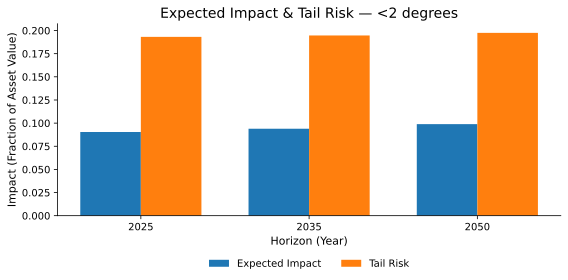

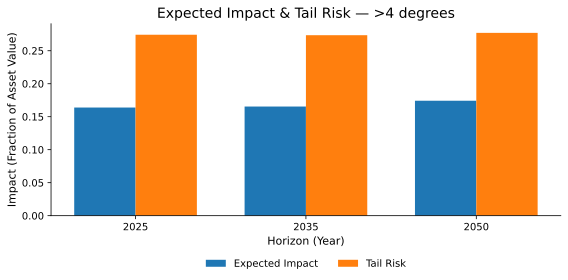

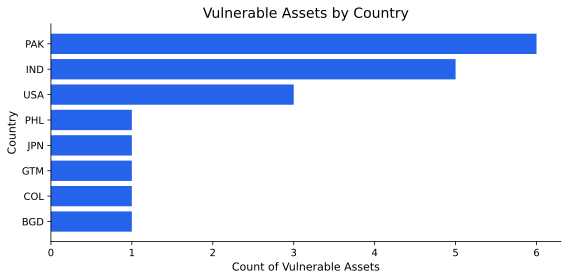

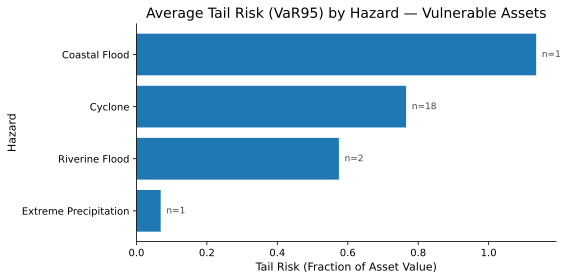

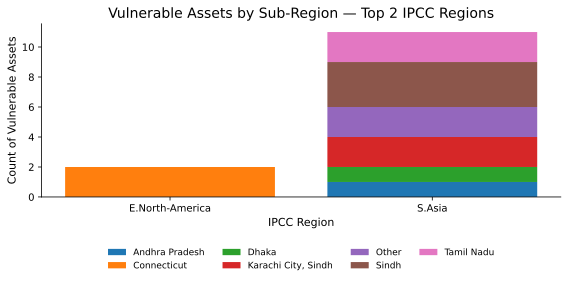

In [ ]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Figures & Maps                                         ║
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Figures for key results:
#   • Clustered bars (Expected Impact & Tail Risk) per scenario
#   • Country distribution of vulnerable assets (horizontal bars)
#   • Hazards among vulnerable assets (horizontal bars with count annotations)
#   • Top-2 IPCC regions → stacked bars of sub-region distribution
#   • Geographic maps of materially vulnerable assets with leading hazards
# Inputs  : merged, leading_hazard_df, vuln_ids, PATHWAYS, HORIZONS, OUTPUT_DIR,
#           MATERIALITY_HORIZON, MATERIALITY_PATHWAYS
# Outputs : PNG figures to OUTPUT_DIR and inline displays

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import re

# ---- Label/Color settings ----
PLOT_METRICS = ["expected_impact", "cvar_95"]
METRIC_LABELS = {
    "expected_impact": "Expected Impact",
    "cvar_95": "Tail Risk",
}
BAR_COLORS = {
    "expected_impact": "#1f77b4",  # muted blue
    "cvar_95": "#ff7f0e",          # orange
}
HAZARD_COLOR = "#1f77b4"
COUNTRY_COLOR = "#2563eb"

# ---- Small helpers ----
def _legend_below(ax, ncol=2):
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=ncol, fontsize=10)

def _clean_axes(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def _coalesce_hazard_cols(df: pd.DataFrame) -> pd.DataFrame:
    if "hazard" not in df.columns:
        if "hazard_x" in df.columns:
            df["hazard"] = df["hazard_x"]
        elif "hazard_y" in df.columns:
            df["hazard"] = df["hazard_y"]
        else:
            df["hazard"] = np.nan
    drop_cols = [c for c in ["hazard_x", "hazard_y"] if c in df.columns]
    if drop_cols:
        df = df.drop(columns=drop_cols)
    return df

# ---- 0) Clustered bars for Expected Impact & Tail Risk (per scenario) ----
def plot_clustered_bars_for_pathway(pathway: str) -> None:
    req_cols = ["pathway", "horizon"] + PLOT_METRICS
    miss = [c for c in req_cols if c not in merged.columns]
    if miss:
        print(f"Skipping bar chart for {pathway}: missing columns {miss}")
        return

    dfp = (
        merged[merged["pathway"] == pathway]
        .groupby(["horizon"], as_index=False)[PLOT_METRICS]
        .mean(numeric_only=True)
        .sort_values("horizon")
    )
    if dfp.empty:
        print(f"No data to plot for pathway {pathway}")
        return

    horizons = dfp["horizon"].to_numpy(dtype=float)
    x = np.arange(len(horizons), dtype=float)
    width = 0.36

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(x - width/2, dfp["expected_impact"], width,
           label=METRIC_LABELS["expected_impact"], color=BAR_COLORS["expected_impact"])
    ax.bar(x + width/2, dfp["cvar_95"], width,
           label=METRIC_LABELS["cvar_95"], color=BAR_COLORS["cvar_95"])

    ax.set_title(f"{METRIC_LABELS['expected_impact']} & {METRIC_LABELS['cvar_95']} — {pathway}", fontsize=14)
    ax.set_xlabel("Horizon (Year)", fontsize=11)
    ax.set_ylabel("Impact (Fraction of Asset Value)", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(dfp["horizon"].astype(int).tolist())
    _clean_axes(ax)
    _legend_below(ax, ncol=2)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/clustered_bars_{pathway}.png", dpi=200, bbox_inches="tight")
    plt.show()

for p in PATHWAYS:
    plot_clustered_bars_for_pathway(p)

# ---- Common scope for “vulnerable assets” at policy horizon/pathways ----
scope_mat = merged[
    (merged["asset_id"].isin(vuln_ids)) &
    (merged["horizon"] == MATERIALITY_HORIZON) &
    (merged["pathway"].isin([p.lower() for p in MATERIALITY_PATHWAYS]))
].copy()

# Join hazards & coalesce
scope_mat = scope_mat.merge(leading_hazard_df, on=["asset_id","pathway","horizon"], how="left")
scope_mat = _coalesce_hazard_cols(scope_mat)

# ---- 1) Country distribution of vulnerable assets (horizontal bars) ----
def plot_country_distribution(df: pd.DataFrame) -> pd.DataFrame:
    country_counts = (
        df.groupby("country")["asset_id"]
          .nunique()
          .reset_index(name="Count of Vulnerable Assets")
          .sort_values("Count of Vulnerable Assets", ascending=True)  # ascending for horizontal bar
    )
    if country_counts.empty:
        print("No vulnerable assets for country distribution.")
        return country_counts

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(country_counts["country"].astype(str), country_counts["Count of Vulnerable Assets"], color=COUNTRY_COLOR)
    ax.set_title("Vulnerable Assets by Country", fontsize=14)
    ax.set_xlabel("Count of Vulnerable Assets", fontsize=11)
    ax.set_ylabel("Country", fontsize=11)
    _clean_axes(ax)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/country_distribution_vulnerable_assets.png", dpi=200)
    plt.show()
    return country_counts

country_counts = plot_country_distribution(scope_mat)

# ---- 2) Hazards among vulnerable assets (horizontal bars with annotations) ----
def plot_hazard_avg_var(df: pd.DataFrame) -> pd.DataFrame:
    # Per-asset VaR and hazard; use max VaR per asset-hazard (conservative view) at policy horizon
    hz_asset = (
        df.groupby(["asset_id","hazard"])["var_95"]
          .max(numeric_only=True)
          .reset_index()
          .rename(columns={"var_95": "asset_var95"})
    )
    if hz_asset.empty:
        print("No hazard data to plot.")
        return hz_asset

    hazard_table = (
        hz_asset.groupby("hazard")
                .agg(**{
                    "Count of Assets at Risk": ("asset_id","nunique"),
                    "Min. VaR": ("asset_var95","min"),
                    "Avg. VaR": ("asset_var95","mean"),
                    "Max. VaR": ("asset_var95","max"),
                })
                .reset_index()
                .sort_values("Avg. VaR", ascending=True)  # ascending for barh
    )

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(hazard_table["hazard"].astype(str), hazard_table["Avg. VaR"], color=HAZARD_COLOR)
    ax.set_title("Average Tail Risk (VaR95) by Hazard — Vulnerable Assets", fontsize=14)
    ax.set_xlabel("Tail Risk (Fraction of Asset Value)", fontsize=11)
    ax.set_ylabel("Hazard", fontsize=11)
    _clean_axes(ax)

    # Annotate counts at the end of each bar
    for i, (y, v, cnt) in enumerate(zip(hazard_table["hazard"], hazard_table["Avg. VaR"], hazard_table["Count of Assets at Risk"])):
        ax.text(v if pd.notna(v) else 0, i, f"  n={int(cnt)}", va="center", fontsize=9, color="#444")

    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/hazards_avg_var_vulnerable_assets.png", dpi=200)
    plt.show()
    return hazard_table

hazard_avg_table = plot_hazard_avg_var(scope_mat)

# ---- 3) Top-2 IPCC regions → stacked bars of sub-region distribution ----
def plot_ipcc_top2_stacked(df: pd.DataFrame, top_subregions_per_region: int = 5) -> tuple[list, pd.DataFrame]:
    if "ipcc_region" not in df.columns:
        print("ipcc_region not present; skipping IPCC region stacked bars.")
        return [], pd.DataFrame()

    # Top 2 IPCC regions by vulnerable asset count
    top_regions = (
        df.groupby("ipcc_region")["asset_id"].nunique()
          .reset_index(name="count")
          .sort_values("count", ascending=False)
          .head(2)["ipcc_region"]
          .tolist()
    )
    if not top_regions:
        print("No IPCC regions found for vulnerable assets.")
        return [], pd.DataFrame()

    # Choose a sub-region-like column (fallbacks)
    candidate_cols = ["sub_region","sub_region_asset","state","state_asset","region","region_asset","city","city_asset"]
    sub_col = next((c for c in candidate_cols if c in df.columns), None)
    if sub_col is None:
        df = df.copy()
        df["Sub-Region"] = "Unknown"
        sub_col = "Sub-Region"
    elif sub_col != "Sub-Region":
        df = df.rename(columns={sub_col: "Sub-Region"})

    # Counts per region-subregion
    counts = (
        df[df["ipcc_region"].isin(top_regions)]
        .groupby(["ipcc_region","Sub-Region"])["asset_id"]
        .nunique()
        .reset_index(name="count")
    )

    # For each region, keep top N subregions and group others
    frames = []
    for reg in top_regions:
        sub = counts[counts["ipcc_region"] == reg].sort_values("count", ascending=False)
        top = sub.head(top_subregions_per_region)
        others_count = sub["count"].iloc[top_subregions_per_region:].sum()
        frames.append(top)
        if others_count > 0:
            frames.append(pd.DataFrame([{"ipcc_region": reg, "Sub-Region": "Other", "count": others_count}]))
    counts_top = pd.concat(frames, ignore_index=True)

    # Pivot for stacked bar
    pivot = counts_top.pivot(index="ipcc_region", columns="Sub-Region", values="count").fillna(0)

    # Plot
    fig, ax = plt.subplots(figsize=(8, 4))
    bottom = np.zeros(len(pivot), dtype=float)
    for col in pivot.columns:
        ax.bar(pivot.index.astype(str), pivot[col].to_numpy(), bottom=bottom, label=col)
        bottom += pivot[col].to_numpy()
    ax.set_title("Vulnerable Assets by Sub-Region — Top 2 IPCC Regions", fontsize=14)
    ax.set_xlabel("IPCC Region", fontsize=11)
    ax.set_ylabel("Count of Vulnerable Assets", fontsize=11)
    _clean_axes(ax)
    # Legend below, potentially many columns
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25),
              ncol=min(4, len(pivot.columns)), fontsize=9)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/ipcc_top2_subregion_stacked.png", dpi=200, bbox_inches="tight")
    plt.show()

    return top_regions, counts_top

ipcc_top2, ipcc_counts = plot_ipcc_top2_stacked(scope_mat, top_subregions_per_region=5)

# ---- Maps: materially vulnerable assets with leading hazard (export at 800x400 px) ----
def map_for(pathway: str, horizon: int) -> None:
    sub = merged.merge(leading_hazard_df, on=["asset_id", "pathway", "horizon"], how="left")
    sub = _coalesce_hazard_cols(sub)
    # Filter to material assets for selected scenario/horizon
    sub = sub[sub["asset_id"].isin(vuln_ids)]
    sub = sub[(sub["pathway"] == pathway) & (sub["horizon"] == horizon)]
    if sub.empty:
        print(f"No materially vulnerable assets for {pathway}/{horizon}")
        return

    fig = px.scatter_geo(
        sub,
        lat="latitude",
        lon="longitude",
        color="hazard",
        color_discrete_sequence=px.colors.qualitative.Set2,
        hover_name="name",
        hover_data={"country": True, "asset_type": True, "hazard": True, "latitude": False, "longitude": False},
        title=f"Materially Vulnerable Assets — {pathway} / {horizon}",
        projection="natural earth",
    )
    fig.update_traces(marker=dict(size=7, line=dict(width=0)))
    fig.update_layout(
        autosize=False,
        margin=dict(l=10, r=10, t=50, b=10),
        legend_title_text="Hazard",
        geo=dict(
            showcountries=True,
            showland=True,
            landcolor="rgb(245,245,245)",
            showocean=True,
            oceancolor="rgb(230, 244, 255)",
        ),
    )
    # Export at ~8x4 inches equivalent (800x400 px)
    fig.write_image(f"{OUTPUT_DIR}/map_material_{pathway}_{horizon}.png", width=800, height=400, scale=1)
    fig.show()

for p in PATHWAYS:
    for h in HORIZONS:
        map_for(p, h)



## Disclosure exports

CSV of material assets with locations and leading hazards.


In [36]:
# ╔════════════════════════════════════════════════════════════════╗
# ║ Block: Disclosure Exports
# ╚════════════════════════════════════════════════════════════════╝
# Purpose : Export disclosure-ready records.
# Inputs  : `merged`, `leading_hazard_df`, `vuln_ids`.
# Outputs : CSV for transparency.


material_assets = merged.merge(leading_hazard_df, on=["asset_id","pathway","horizon"], how="left")

# Coalesce duplicated hazard columns to single names
if "hazard" not in material_assets.columns:
    if "hazard_x" in material_assets.columns:
        material_assets["hazard"] = material_assets["hazard_x"]
    elif "hazard_y" in material_assets.columns:
        material_assets["hazard"] = material_assets["hazard_y"]
    else:
        material_assets["hazard"] = np.nan

if "hazard_score" not in material_assets.columns:
    if "hazard_score_x" in material_assets.columns:
        material_assets["hazard_score"] = material_assets["hazard_score_x"]
    elif "hazard_score_y" in material_assets.columns:
        material_assets["hazard_score"] = material_assets["hazard_score_y"]
    else:
        material_assets["hazard_score"] = np.nan

# (optional) drop the noisy _x/_y columns to avoid future confusion
material_assets = material_assets.drop(
    columns=[c for c in ["hazard_x","hazard_y","hazard_score_x","hazard_score_y"] if c in material_assets.columns]
)

# Keep only materially vulnerable assets
material_assets = material_assets[material_assets["asset_id"].isin(vuln_ids)]

# Now this select will work because 'hazard' exists
material_assets = material_assets.loc[:, [
    "asset_id","name","asset_type","country","latitude","longitude","pathway","horizon","hazard"
]]
material_assets = material_assets.drop_duplicates().sort_values(["pathway","horizon","country","asset_type"])
material_assets.to_csv(f"{OUTPUT_DIR}/{COMPANY_NAME}_material_assets_with_locations_and_hazards.csv", index=False)

# print("Saved all figures & tables to:", OUTPUT_DIR)
